<a href="https://colab.research.google.com/github/s61711299-sketch/MSSP6070/blob/main/Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Q1

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
df=pd.read_csv('/content/drive/MyDrive/data.csv',encoding='latin1')
num_cols=['MAT_S11','CR_S11','CC_S11','BIO_S11','ENG_S11','QR_PRO','CR_PRO','CC_PRO','ENG_PRO','WC_PRO','FEP_PRO','G_SC','PERCENTILE','2ND_DECILE','QUARTILE']
for c in num_cols:
  if c in df.columns:
    df[c]=pd.to_numeric(df[c],'coerce')


Mounted at /content/drive


In [ ]:
import numpy as np
edu_mapping={
    '0':0,
    'Ninguno':0,
    'Incomplete primary':1,
    'Complete primary':2,
    'Incomplete Secundary':3,
    'Complete Secundary':4,
    'Incomplete technical or technological':5,
    'Complete technique or technology':6,
    'Incomplete Professional Education':7,
    'Complete professional education':8,
    'Postgraduate education':9,
    'Not sure':np.nan}
for col in ['EDU_FATHER', 'EDU_MOTHER']:
    if col in df.columns:
        df[col+'_NUM']=df[col].astype(str).str.strip().map(edu_mapping)
if 'EDU_FATHER_NUM' in df.columns and 'EDU_MOTHER_NUM' in df.columns:
    df['PARENT_EDU_AVG'] = df[['EDU_FATHER_NUM', 'EDU_MOTHER_NUM']].mean(axis=1)
    df['PARENT_EDU_MAX'] = df[['EDU_FATHER_NUM', 'EDU_MOTHER_NUM']].max(axis=1)

In [ ]:
from scipy import stats
parent_edu_stats_df=df.groupby('PARENT_EDU_AVG')['G_SC'].agg(['count','mean','std','median']).round(2)
from google.colab import files
parent_edu_stats_df.to_csv('parent_edu_stats.csv')
files.download('parent_edu_stats.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
father_edu_stats_df=df.groupby('EDU_FATHER_NUM')['G_SC'].agg(['count','mean','std','median']).round(2)
father_edu_stats_df.to_csv('father_edu_stats.csv')
files.download('father_edu_stats.csv')
groups_f=[g['G_SC'].dropna().values for _, g in df.groupby('EDU_FATHER_NUM') if len(g['G_SC'].dropna()) > 0]
f_stat_f,p_val_f=stats.f_oneway(*groups_f)
print(f"\nfather education ANOVA: F={f_stat_f:.3f}, p={p_val_f:.5f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


father education ANOVA: F=113.337, p=0.00000


In [ ]:
mother_edu_stats_df=df.groupby('EDU_MOTHER_NUM')['G_SC'].agg(['count','mean','std','median']).round(2)
mother_edu_stats_df.to_csv('mother_edu_stats.csv')
files.download('mother_edu_stats.csv')
groups_m=[g['G_SC'].dropna().values for _, g in df.groupby('EDU_MOTHER_NUM') if len(g['G_SC'].dropna()) > 0]
f_stat_m,p_val_m=stats.f_oneway(*groups_m)
print(f"mother education ANOVA: F={f_stat_m:.3f}, p={p_val_m:.5f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

mother education ANOVA: F=112.692, p=0.00000


In [ ]:
corr_cols=['G_SC', 'EDU_FATHER_NUM', 'EDU_MOTHER_NUM', 'PARENT_EDU_AVG']
spearman_df=df[corr_cols].corr(method='spearman').round(3)
spearman_df.to_csv('spearman_correlation.csv')
files.download('spearman_correlation.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
if 'GENDER' in df.columns:
    df['GENDER']=df['GENDER'].astype(str).str.strip().str.upper()
    df['GENDER']=df['GENDER'].replace({'0': np.nan, 'NAN': np.nan})
stratum_mapping={'0':np.nan,
    'Stratum 1':1,
    'Stratum 2':2,
    'Stratum 3':3,
    'Stratum 4':4,
    'Stratum 5':5,
    'Stratum 6':6}
if 'STRATUM' in df.columns:
    df['STRATUM_NUM']=df['STRATUM'].astype(str).str.strip().map(stratum_mapping)
sisben_mapping={'0':np.nan,
    'Level 1':1,
    'Level 2':2,
    'Level 3':3,
    'Esta clasificada en otro Level del SISBEN':np.nan,
    'It is not classified by the SISBEN':np.nan}
if 'SISBEN' in df.columns:
    df['SISBEN_NUM']=df['SISBEN'].astype(str).str.strip().map(sisben_mapping)
revenue_mapping={'0':np.nan,
    'less than 1 LMMW':1,
    'Between 1 and less than 2 LMMW':2,
    'Between 2 and less than 3 LMMW':3,
    'Between 3 and less than 5 LMMW':4,
    'Between 5 and less than 7 LMMW':5,
    'Between 7 and less than 10 LMMW':6,
    '10 or more LMMW':7}
if 'REVENUE' in df.columns:
    df['REVENUE_NUM']=df['REVENUE'].astype(str).str.strip().map(revenue_mapping)

In [ ]:
import statsmodels.formula.api as smf
formula="G_SC~EDU_FATHER_NUM+EDU_MOTHER_NUM+C(GENDER)+STRATUM_NUM+SISBEN_NUM+REVENUE_NUM"
model=smf.ols(formula,data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   G_SC   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.025
Method:                 Least Squares   F-statistic:                     20.89
Date:                Sat, 26 Sep 2026   Prob (F-statistic):           2.69e-24
Time:                        23:29:38   Log-Likelihood:                -20632.
No. Observations:                4582   AIC:                         4.128e+04
Df Residuals:                    4575   BIC:                         4.132e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        143.1541      1.175    121.

Q2

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")
plt.rcParams['figure.figsize']=(10,6)
df_stratum=df.dropna(subset=['STRATUM_NUM','G_SC'])
stratum_stats=df_stratum.groupby('STRATUM_NUM')['G_SC'].agg(['count','mean','std','median']).round(2)
stratum_stats.to_csv('stratum_stats.csv')
files.download('stratum_stats.csv')
groups_stratum=[g['G_SC'].values for _, g in df_stratum.groupby('STRATUM_NUM')]
f_stat_s,p_val_s=stats.f_oneway(*groups_stratum)
print(f"\nSTRATUM ANOVA:F={f_stat_s:.3f},p={p_val_s:.5f}")
if p_val_s<0.05:
    print("significant")
else:
    print("insignificant")
df_sisben=df.dropna(subset=['SISBEN_NUM','G_SC'])
sisben_stats=df_sisben.groupby('SISBEN_NUM')['G_SC'].agg(['count','mean','std','median']).round(2)
sisben_stats.to_csv('sisben_stats.csv')
files.download('sisben_stats.csv')
groups_sisben=[g['G_SC'].values for _, g in df_sisben.groupby('SISBEN_NUM')]
f_stat_sis, p_val_sis=stats.f_oneway(*groups_sisben)
print(f"\nSISBEN ANOVA:F={f_stat_sis:.3f},p={p_val_sis:.5f}")
if p_val_sis<0.05:
    print("significant")
else:
    print("insignificant")
df_revenue=df.dropna(subset=['REVENUE_NUM','G_SC'])
revenue_stats=df_revenue.groupby('REVENUE_NUM')['G_SC'].agg(['count', 'mean', 'std', 'median']).round(2)
revenue_stats.to_csv('revenue_stats.csv')
files.download('revenue_stats.csv')
groups_revenue=[g['G_SC'].values for _, g in df_revenue.groupby('REVENUE_NUM')]
f_stat_rev,p_val_rev=stats.f_oneway(*groups_revenue)
print(f"\nREVENUE ANOVA:F={f_stat_rev:.3f},p={p_val_rev:.5f}")
if p_val_rev<0.05:
    print("significant")
else:
    print("insignificant")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


STRATUM ANOVA:F=286.064,p=0.00000
significant


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


SISBEN ANOVA:F=34.940,p=0.00000
significant


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


REVENUE ANOVA:F=254.683,p=0.00000
significant


/tmp/ipykernel_1250/3816682311.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='STRATUM_NUM',y='G_SC',data=df_stratum,palette="Blues")


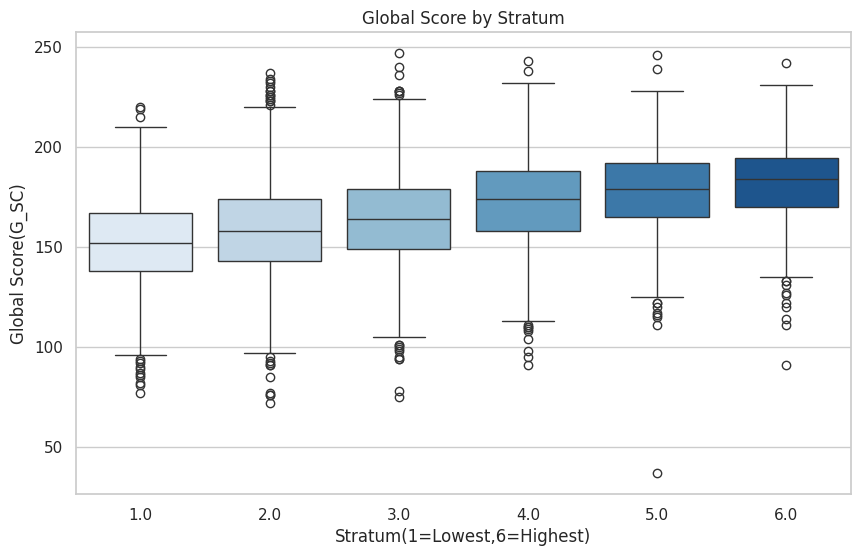

/tmp/ipykernel_1250/3816682311.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='SISBEN_NUM',y='G_SC',data=df_sisben,palette="Greens")


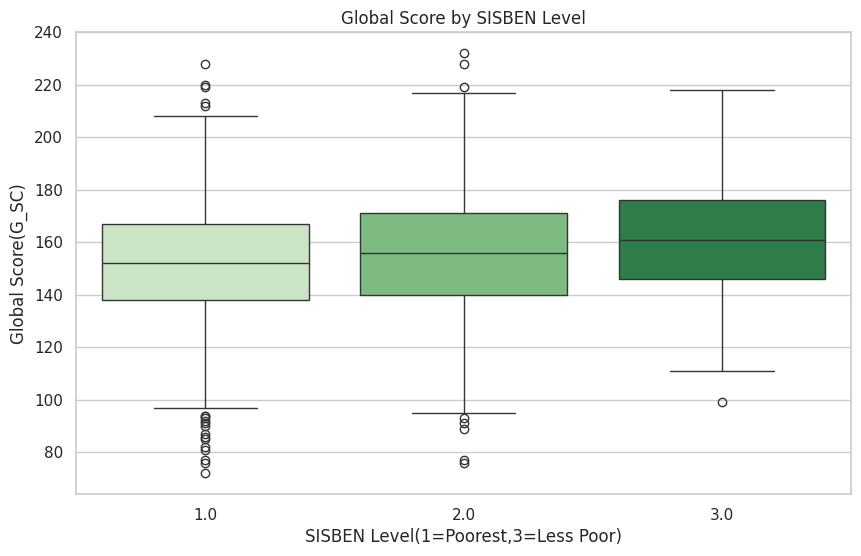

/tmp/ipykernel_1250/3816682311.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='REVENUE_NUM',y='G_SC',data=df_revenue,palette="Oranges")


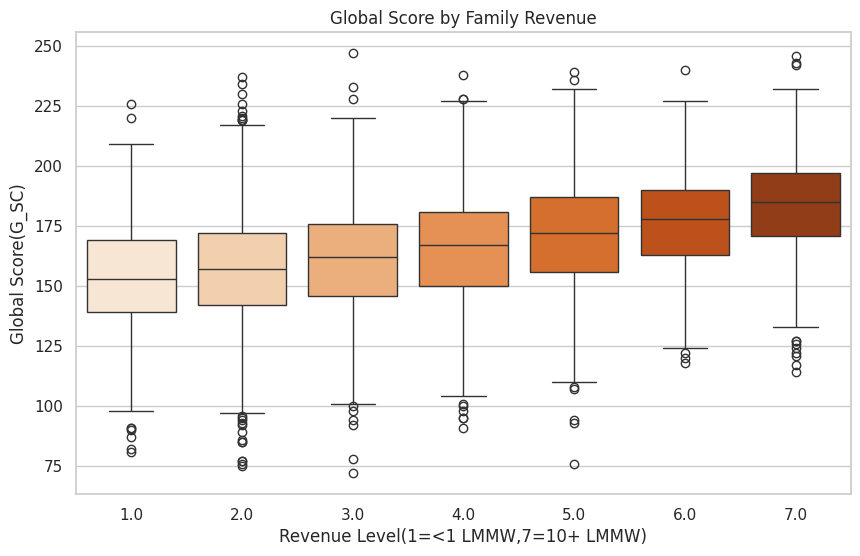

In [ ]:
plt.figure()
sns.boxplot(x='STRATUM_NUM',y='G_SC',data=df_stratum,palette="Blues")
plt.title('Global Score by Stratum')
plt.xlabel('Stratum(1=Lowest,6=Highest)')
plt.ylabel('Global Score(G_SC)')
plt.savefig('/content/drive/MyDrive/stratum_boxplot.png')
plt.show()
plt.figure()
sns.boxplot(x='SISBEN_NUM',y='G_SC',data=df_sisben,palette="Greens")
plt.title('Global Score by SISBEN Level')
plt.xlabel('SISBEN Level(1=Poorest,3=Less Poor)')
plt.ylabel('Global Score(G_SC)')
plt.savefig('/content/drive/MyDrive/sisben_boxplot.png')
plt.show()
plt.figure()
sns.boxplot(x='REVENUE_NUM',y='G_SC',data=df_revenue,palette="Oranges")
plt.title('Global Score by Family Revenue')
plt.xlabel('Revenue Level(1=<1 LMMW,7=10+ LMMW)')
plt.ylabel('Global Score(G_SC)')
plt.savefig('/content/drive/MyDrive/revenue_boxplot.png')
plt.show()

Q3

In [ ]:
df_gender=df[df['GENDER'].isin(['F','M'])].dropna(subset=['G_SC']).copy()
gender_stats=df_gender.groupby('GENDER')['G_SC'].agg(['count','mean','std','median','min','max']).round(2)
gender_stats.to_csv('gender_stats.csv')
files.download('gender_stats.csv')
male_scores=df_gender.loc[df_gender['GENDER']=='M','G_SC']
female_scores=df_gender.loc[df_gender['GENDER']=='F','G_SC']
t_stat,p_val=stats.ttest_ind(male_scores,female_scores,equal_var=False)
print("t test")
print(f"T:{t_stat:.3f}")
print(f"P:{p_val:.5f}")
print(f"Male Average:{male_scores.mean():.2f}")
print(f"Female Average:{female_scores.mean():.2f}")
print(f"Difference(Male-Female):{male_scores.mean()-female_scores.mean():.2f}")
if p_val < 0.05:
    print("significant")
else:
    print("insignificant")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

t test
T:5.777
P:0.00000
Male Average:163.69
Female Average:161.28
Difference(Male-Female):2.41
significant


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

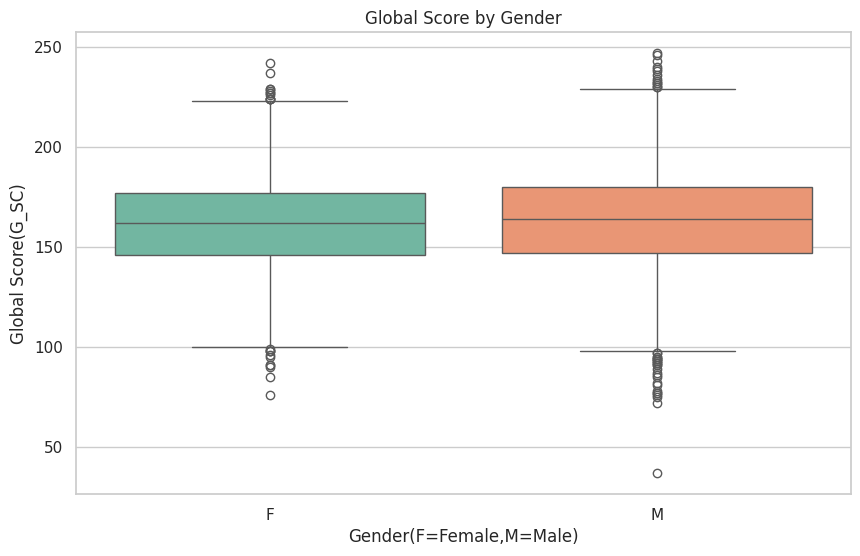

In [ ]:
test_cols=['MAT_S11','CR_S11','CC_S11','BIO_S11','ENG_S11','QR_PRO','CR_PRO','CC_PRO','ENG_PRO','WC_PRO','FEP_PRO','G_SC','PERCENTILE']
test_cols=[c for c in test_cols if c in df_gender.columns]
subject_means=df_gender.groupby('GENDER')[test_cols].mean().T.round(2)
subject_means['Difference(M-F)']=subject_means['M']-subject_means['F']
subject_means.to_csv('subject_means.csv')
files.download('subject_means.csv')
plt.figure()
sns.boxplot(x='GENDER',y='G_SC',data=df_gender,hue='GENDER',palette="Set2",legend=False)
plt.title('Global Score by Gender')
plt.xlabel('Gender(F=Female,M=Male)')
plt.ylabel('Global Score(G_SC)')
plt.savefig('/content/drive/MyDrive/gender_boxplot.png')
plt.show()